# C2 yield projection, 2041–60

Track C, Apetit Climate & Nature Navigator 2026.

This notebook projects contract-crop yields for 2041–60 under the three climate scenarios (ssp126, ssp245 and ssp585), and the chance of a bad year in each. It is step 8 of the farm climate-risk recipe; step 9 turns its results into euros.

The package gives one 20-year weather run per scenario, which mixes the climate signal with chance good and bad summers. So the projection builds many seasons instead. Every season from 1991–2020 is shifted to each scenario's 2041–60 climate, using the package's monthly changes:

- temperatures rise by that month's change;
- rain is scaled by that month's factor;
- evaporation is recalculated for the warmer days.

Each shifted season then goes through the same steps as the history: the tuned crop calendar (so sowing and growth move with the warmth), the soil-water model, the stress measures and the yield model.

To isolate the climate, everything else is held at today's level:

- the 2025 contract parcels;
- each farm's recent management;
- the yearly trend at 2026.

The same model run on the unshifted 1991–2020 seasons is the baseline, so model bias cancels in every comparison. A bad year is a season whose area-weighted yield is below 80% of the baseline average, the package's definition.

It needs the outputs of `c1_weather_features.ipynb` and `c1_yield_model.ipynb`. The code is in `climateproj.py`.

## 0. Setup

In [1]:
from pathlib import Path
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cropweather as cw
import yieldcv as cv
import yieldmodel as ym
import climateproj as cp

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
PKG = Path(os.environ.get("CCN_PKG", "../APETIT_CLIMATE_NATURE_NAVIGATOR_2026")).resolve()
OUT, RESULTS = Path("outputs"), Path("results")
for f in ["yield_model.json", "c1_model_table.csv", "c1_parcel_year_features.parquet"]:
    assert (OUT / f).exists(), f"run c1_yield_model.ipynb first ({f} missing)"
assert (RESULTS / "crop_params.json").exists(), "run c1_weather_features.ipynb first"

UNITS = [("FI_SW", "pea"), ("SE_SKANE", "pea"), ("FI_SW", "turnip_rape"),
         ("FI_SW", "potato"), ("FI_SW", "carrot"), ("FI_SW", "spinach")]
LABEL = {("FI_SW", "pea"): "Pea, Finland", ("SE_SKANE", "pea"): "Pea, Sweden", ("FI_SW", "turnip_rape"): "Turnip rape, Finland",
         ("FI_SW", "potato"): "Potato, Finland", ("FI_SW", "carrot"): "Carrot, Finland", ("FI_SW", "spinach"): "Spinach, Finland"}
PREFIX = {"FI_SW": "GF", "SE_SKANE": "GS"}
TREND_YEAR = 2026
REPS = 50          # simulated outcomes per season

## 1. Build the weather sets

Seven sets per weather cell: the 30 recorded seasons of 1991–2020, the same 30 seasons shifted to each scenario, and the package's own 20-season run for each scenario as a check. The table shows what a summer looks like in each set.

In [2]:
keys, arr = cw.load_weather(PKG / "data/04_climate/weather_daily_1991_2060.parquet")
signals = pd.read_csv(PKG / "data/04_climate/climate_change_signals.csv")
k, a = cp.ensemble(keys, arr, signals)
del arr
stress, sat = cw.soil_water(a)
print(f"{len(k)} weather series in", k["scenario"].nunique(), "sets")
cp.summer_climate(k, a).rename(columns={"tmean_c": "June-Aug mean (C)", "hot_days": "days above 27 C", "rain_mm": "June-Aug rain (mm)"})

15120 weather series in 7 sets


,,June-Aug mean (C),days above 27 C,June-Aug rain (mm)
region,scenario,,,
FI_SW,baseline,16.290001,3.53,193.160004
SE_SKANE,baseline,16.600000,2.22,178.059998
FI_SW,ssp126,17.719999,8.20,198.949997
SE_SKANE,ssp126,18.030001,6.21,183.399994
FI_SW,ssp126_run,16.580000,2.65,218.600006
SE_SKANE,ssp126_run,17.670000,4.28,216.369995
FI_SW,ssp245,18.090000,10.02,201.470001
SE_SKANE,ssp245,18.400000,7.87,185.820007
FI_SW,ssp245_run,17.610001,6.87,199.410004


The shifted seasons follow the package's stated changes exactly: about 1.4–2.5 °C warmer summers and two to four times as many hot days, with slightly more rain. The delivered runs match under ssp585, but under ssp126 and ssp245 they run 0.5–1 °C cooler in Finland. A single 20-year run has its own chance warm and cool spells, which is why the shifted seasons are the main result.

## 2. Run the 2025 contract parcels through every season

Each 2025 contract parcel is paired with every season in every set, using its own weather cell, soil and farm. Management is each farm's recent practice, and the trend is held at 2026.

In [3]:
params = json.load(open(RESULTS / "crop_params.json"))["crop_params"]
MODELS = json.load(open(OUT / "yield_model.json"))
hist = pd.read_csv(OUT / "c1_model_table.csv")
pyf = pd.read_parquet(OUT / "c1_parcel_year_features.parquet")
p2025 = pyf[pyf["status"].eq("declared") & pyf["year"].eq(2025)][
    ["parcel_id", "farm_id", "region", "crop", "parcel_area_ha", "soil_class_soilmap", "clay_pct_soilmap", "slope_pct", "cell_id"]]
per_farm, unit_mgmt = ym.management_defaults(hist)

def crop_params(u):
    p = params[f"{u[0]}/{u[1]}"]
    return cw.CropParams(**{**p, "flower": tuple(p["flower"]), "sensitive": tuple(p["sensitive"])})

def unit_rows(u):
    r, c = u
    idx = np.where(k["cell_id"].str.startswith(PREFIX[r]).values)[0]
    f = cw.crop_features(k, a, stress, sat, crop_params(u), idx)
    seasons = k.iloc[idx][["scenario", "year"]].drop_duplicates()
    x = cw.to_parcels(f, p2025[p2025["region"].eq(r) & p2025["crop"].eq(c)].merge(seasons, how="cross"))
    x = x.join(ym.parcel_soil_features(x)).merge(per_farm, on=["region", "farm_id", "crop"], how="left")
    for col in ym.MANAGEMENT:
        x[col] = pd.to_numeric(x[col], errors="coerce").fillna(unit_mgmt[col].get(u, np.nan))
    x["sprays"] = x["sprays"].fillna(0.0)
    x = cv.add_model_columns(x)
    x["year_c"] = TREND_YEAR - 2019
    m = MODELS[f"{r}/{c}"]
    x["log_yield"] = np.log(ym.predict(m, x) / m["smearing"])
    return x

ROWS = {u: unit_rows(u) for u in UNITS}
pd.DataFrame({LABEL[u]: {"2025 parcels": x["parcel_id"].nunique(), "farms": x["farm_id"].nunique(),
                         "area (ha)": round(p2025[p2025["region"].eq(u[0]) & p2025["crop"].eq(u[1])]["parcel_area_ha"].sum()),
                         "parcel-seasons": len(x)} for u, x in ROWS.items()}).T

,2025 parcels,farms,area (ha),parcel-seasons
"Pea, Finland",389,119,2015,70020
"Pea, Sweden",920,298,4973,165600
"Turnip rape, Finland",950,230,5025,171000
"Potato, Finland",57,15,328,10260
"Carrot, Finland",42,12,227,7560
"Spinach, Finland",52,16,359,9360


## 3. How the warming changes the season

Averages over all parcels and seasons. Warmer springs bring sowing a few days earlier, and faster growth brings the crop to maturity two to five weeks earlier. Flowering moves into earlier, cooler weeks, so heat at flowering rises much less than summer heat overall. Extra rain roughly offsets the extra evaporation, so drought stress hardly moves. A warmer May matters for turnip rape, because that is when pollen beetles attack.

In [4]:
SHOW = {"sow_doy": "sown (day of year)", "mat_doy": "ready (day of year)", "heat_days_27": "heat days at flowering",
        "drought_stage": "drought stress", "harvest_rain_14_mm": "rain before harvest (mm)", "may_tmean_c": "May mean (C)"}
order = ["baseline", "ssp126", "ssp245", "ssp585"]
season = pd.concat({LABEL[u]: x.groupby("scenario")[list(SHOW)].mean().loc[order].rename(columns=SHOW) for u, x in ROWS.items()})
season.round(2)

sown (day of year)  ready (day of year)  heat days at flowering  drought stress  rain before harvest (mm)  May mean (C)
                     scenario                                                                                                                         
Pea, Finland         baseline              113.36               231.07                    2.00            0.43                 23.969999         10.73
                     ssp126                110.96               217.57                    2.58            0.44                 33.200001         12.03
                     ssp245                110.56               214.65                    2.71            0.44                 33.270000         12.43
                     ssp585                110.22               209.91                    3.01            0.45                 30.190001         13.03
Pea, Sweden          baseline              117.59               188.85                    0.06            0.48                 28.100000         11.04
                     ssp126                112.07               179.78                    0.40            0.49                 27.760000         12.34
                     ssp245                111.32               177.62                    0.40            0.48                 28.559999         12.74
                     ssp585                110.73               174.16                    0.36            0.49                 27.290001         13.34
Turnip rape, Finland baseline              113.83               253.06                    1.83            0.42                 22.320000         10.57
                     ssp126                111.14               234.47                    2.17            0.43                 26.090000         11.87
                     ssp245                110.76               230.41                    2.21            0.43                 26.760000         12.27
                     ssp585                110.36               224.09                    2.55            0.44                 33.759998         12.87
Potato, Finland      baseline              124.40               266.94                    2.45            0.42                 23.879999         10.75
                     ssp126                121.95               246.63                    3.58            0.44                 20.730000         12.05
                     ssp245                121.67               241.71                    3.76            0.44                 23.850000         12.45
                     ssp585                121.39               234.33                    4.32            0.46                 25.290001         13.05
Carrot, Finland      baseline              121.97               241.53                    0.18            0.43                 22.230000         10.75
                     ssp126                117.52               226.45                    0.25            0.44                 28.900000         12.05
                     ssp245                116.82               223.09                    0.30            0.44                 31.040001         12.45
                     ssp585                116.33               217.77                    0.56            0.44                 32.959999         13.05
Spinach, Finland     baseline              120.76               169.53                    0.02            0.34                 30.260000         10.73
                     ssp126                115.09               161.65                    0.11            0.32                 28.430000         12.03
                     ssp245                113.79               159.52                    0.09            0.31                 28.530001         12.43
                     ssp585                112.19               156.71                    0.05            0.30                 27.940001         13.03

## 4. Projected yields and bad years

Each season is simulated 50 times, adding the model's leftover error: one draw shared by all farms in the season and one draw per farm. Ranges are 90% intervals from resampling the 30 seasons, each together with its shifted versions. They show how firmly the past seasons pin the answer down, but not the uncertainty in the model's coefficients.

In [5]:
DRAWS, rows = {}, []
for u, x in ROWS.items():
    d = cp.simulate(x[["farm_id", "scenario", "year", "parcel_area_ha", "log_yield"]], MODELS[f"{u[0]}/{u[1]}"], reps=REPS)
    DRAWS[u] = d
    s = cp.summarise(d).merge(cp.bootstrap(d), on="scenario")
    s.insert(0, "region", u[0]); s.insert(1, "crop", u[1])
    rows.append(s)
proj = pd.concat(rows, ignore_index=True)
ens = proj[proj["scenario"].isin(order)].copy()
ens["unit"] = [LABEL[(r, c)] for r, c in zip(ens["region"], ens["crop"])]
table = ens.pivot(index="unit", columns="scenario", values="mean_yield_change_pct")[order[1:]].add_prefix("yield change % ")
table = table.join(ens.pivot(index="unit", columns="scenario", values="p_bad_year")[order].mul(100).add_prefix("bad-year chance % "))
table.loc[[LABEL[u] for u in UNITS]].round(1)

scenario,yield change % ssp126,yield change % ssp245,yield change % ssp585,bad-year chance % baseline,bad-year chance % ssp126,bad-year chance % ssp245,bad-year chance % ssp585
unit,,,,,,,
"Pea, Finland",-2.1,-2.6,-3.3,9.8,16.1,16.7,16.2
"Pea, Sweden",0.2,0.3,0.3,1.4,0.5,0.8,0.3
"Turnip rape, Finland",-2.3,-2.9,-4.8,5.7,10.7,12.3,16.3
"Potato, Finland",-0.4,-1.1,-2.1,0.8,0.6,0.2,0.6
"Carrot, Finland",-0.4,-0.4,-0.8,0.1,0.0,0.0,0.0
"Spinach, Finland",0.5,1.2,2.2,0.1,3.3,0.5,0.0


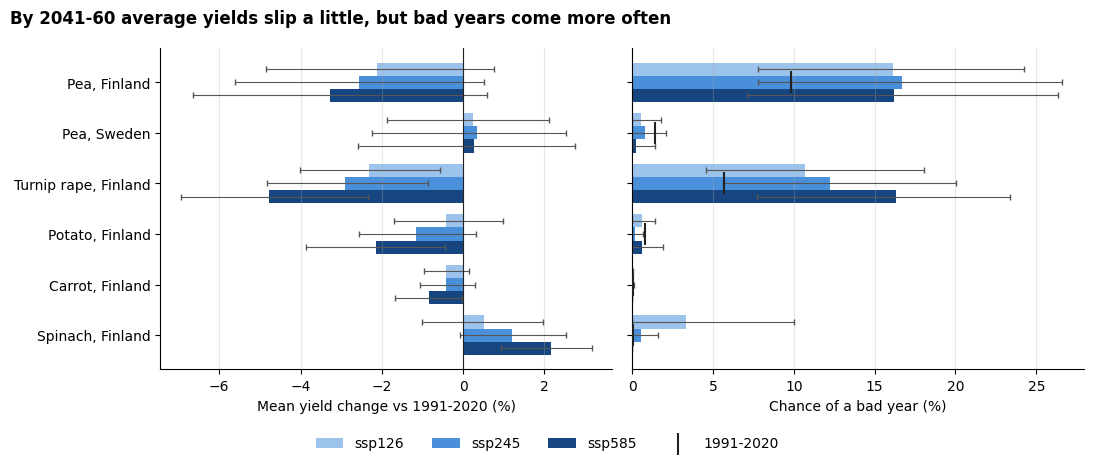

In [6]:
colors = {"ssp126": "#9cc3ec", "ssp245": "#4a8fd9", "ssp585": "#16457f"}
units = [LABEL[u] for u in UNITS][::-1]
y = np.arange(len(units)); h = 0.26
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for i, s in enumerate(order[1:]):
    e = ens[ens["scenario"].eq(s)].set_index("unit").loc[units]
    off = (1 - i) * h
    ax1.barh(y + off, e["mean_yield_change_pct"], h, color=colors[s], label=s)
    ax1.errorbar(e["mean_yield_change_pct"], y + off, xerr=[e["mean_yield_change_pct"] - e["change_low_pct"], e["change_high_pct"] - e["mean_yield_change_pct"]],
                 fmt="none", ecolor="#555555", elinewidth=0.8, capsize=2)
    ax2.barh(y + off, 100 * e["p_bad_year"], h, color=colors[s])
    ax2.errorbar(100 * e["p_bad_year"], y + off, xerr=[100 * (e["p_bad_year"] - e["p_bad_low"]), 100 * (e["p_bad_high"] - e["p_bad_year"])],
                 fmt="none", ecolor="#555555", elinewidth=0.8, capsize=2)
b = ens[ens["scenario"].eq("baseline")].set_index("unit").loc[units]
ax2.scatter(100 * b["p_bad_year"], y, marker="|", s=260, color="#222222", zorder=3, label="1991-2020")
ax1.axvline(0, color="#222222", lw=0.8)
ax1.set_yticks(y); ax1.set_yticklabels(units)
ax1.set_xlabel("Mean yield change vs 1991-2020 (%)"); ax2.set_xlabel("Chance of a bad year (%)")
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", alpha=0.3)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
fig.legend(h1 + h2, l1 + l2, loc="lower center", ncol=4, frameon=False)
fig.suptitle("By 2041-60 average yields slip a little, but bad years come more often", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(rect=[0, 0.07, 1, 1])
fig.savefig(RESULTS / "yield_projection_2041_2060.png", dpi=150, bbox_inches="tight")
plt.show()

Average yields change little. Finnish pea and turnip rape lose a few percent, and Swedish pea and the vegetables hardly move. The risk shows in the bad years, seasons more than 20% below the old average:

- Finnish turnip rape: from about 6% of seasons to 11–16%, rising with each warmer scenario, mainly through warmer Mays and pollen beetles.
- Finnish pea: from about 10% to about 16% under all three scenarios, mainly through heat at flowering.
- Swedish pea and the vegetables: bad years stay rare.

Turnip rape's decline holds across the whole range in every scenario. Finnish pea's decline is likely but not certain, since its range still reaches just above zero. Bad years are what hurt supply, and what step 9 prices.

## 5. Check against the package's own runs

The same model on the package's single 2041–60 run for each scenario. With 20 seasons and their chance warm or cool spells, these should land near the shifted-season results but not exactly on them.

In [7]:
chk = proj.copy()
chk["unit"] = [LABEL[(r, c)] for r, c in zip(chk["region"], chk["crop"])]
chk["set"] = np.where(chk["scenario"].str.endswith("_run"), "delivered run", "shifted seasons")
chk["ssp"] = chk["scenario"].str.replace("_run", "", regex=False)
chk = chk[chk["ssp"].ne("baseline")]
cmp = chk.pivot_table(index=["unit", "ssp"], columns="set", values=["mean_yield_change_pct", "p_bad_year"])
cmp.loc[[LABEL[u] for u in UNITS]].round(3)

mean_yield_change_pct                    p_bad_year                
set                                 delivered run shifted seasons delivered run shifted seasons
unit                 ssp                                                                       
Pea, Finland         ssp126                -0.045          -2.120         0.079           0.161
                     ssp245                -2.566          -2.566         0.151           0.167
                     ssp585                -5.477          -3.279         0.067           0.162
Pea, Sweden          ssp126                 5.629           0.238         0.004           0.005
                     ssp245                 4.460           0.340         0.002           0.008
                     ssp585                 2.438           0.272         0.000           0.003
Turnip rape, Finland ssp126                -0.639          -2.308         0.050           0.107
                     ssp245                -3.795          -2.901         0.005           0.123
                     ssp585                -6.998          -4.774         0.052           0.163
Potato, Finland      ssp126                 3.417          -0.426         0.001           0.006
                     ssp245                -1.488          -1.147         0.000           0.002
                     ssp585                -3.185          -2.142         0.000           0.006
Carrot, Finland      ssp126                -1.256          -0.411         0.000           0.000
                     ssp245                -1.009          -0.427         0.000           0.000
                     ssp585                 0.383          -0.842         0.001           0.000
Spinach, Finland     ssp126                 1.480           0.524         0.000           0.033
                     ssp245                 0.629           1.197         0.003           0.005
                     ssp585                -0.203           2.172         0.002           0.000

Mean changes agree within about 5 points. The largest gap is Swedish pea, where the delivered runs are wetter than the shifted seasons and come out 2–5% better. The single runs mostly show fewer bad years for the Finnish crops. Twenty seasons is a small sample for something that happens one year in six to ten, which is why the shifted seasons are the main result.

## 6. Where the model is stretched

The model learned from 2012–2026. A projected parcel-season counts as stretched when one of the stress measures its crop's model uses is outside anything recorded on that crop's parcels. Results are less certain where this share is high.

In [8]:
KEY = ["heat_days_27", "drought_stage", "drought_early", "harvest_rain_14_mm", "may_tmean_c"]
rows = []
for u, x in ROWS.items():
    used = [f for f in KEY if MODELS[f"{u[0]}/{u[1]}"]["beta"].get(f, 0) != 0]
    rec = pyf[pyf["status"].eq("declared") & pyf["region"].eq(u[0]) & pyf["crop"].eq(u[1])]
    lo, hi = rec[used].min(), rec[used].max()
    for s in order[1:]:
        xs = x[x["scenario"].eq(s)]
        out = (xs[used] < lo) | (xs[used] > hi)
        rows.append({"unit": LABEL[u], "scenario": s, "stretched parcel-seasons (%)": 100 * out.any(axis=1).mean(),
                     "most often": out.mean().idxmax() if out.any(axis=1).any() else "none"})
st = pd.DataFrame(rows)
stretch = st.pivot(index="unit", columns="scenario", values="stretched parcel-seasons (%)").loc[[LABEL[u] for u in UNITS]]
stretch = stretch.round(1).astype(str) + "% (" + st.pivot(index="unit", columns="scenario", values="most often").loc[stretch.index] + ")"
stretch

scenario,ssp126,ssp245,ssp585
unit,,,
"Pea, Finland",5.3% (harvest_rain_14_mm),3.7% (harvest_rain_14_mm),2.5% (harvest_rain_14_mm)
"Pea, Sweden",1.7% (harvest_rain_14_mm),2.7% (harvest_rain_14_mm),3.6% (harvest_rain_14_mm)
"Turnip rape, Finland",5.4% (may_tmean_c),4.9% (may_tmean_c),6.1% (may_tmean_c)
"Potato, Finland",2.0% (harvest_rain_14_mm),3.6% (harvest_rain_14_mm),3.1% (harvest_rain_14_mm)
"Carrot, Finland",8.2% (drought_stage),9.6% (drought_stage),10.1% (heat_days_27)
"Spinach, Finland",6.9% (harvest_rain_14_mm),7.6% (harvest_rain_14_mm),5.1% (harvest_rain_14_mm)


The model stays inside its recorded range for more than 90% of parcel-seasons in every crop and scenario. Where it is stretched, the cause is mostly rain before harvest above anything recorded, or, for turnip rape, Mays warmer than any recorded. Carrot is stretched most, at 8–10%, and it also has the least data, so its results are the least certain.

## 7. Checks
If any check fails, the notebook stops before writing anything.

In [9]:
template = pd.read_csv(PKG / "tasks/templates/C2_climate_yield_risk_submission.csv")
sub = template.drop(columns=["mean_yield_change_pct", "p_bad_year"]).merge(
    ens[["region", "crop", "scenario", "mean_yield_change_pct", "p_bad_year"]], on=["region", "crop", "scenario"], how="left")
checks = {
    "every C2 template row has a result": sub[["mean_yield_change_pct", "p_bad_year"]].notna().all().all() and len(sub) == len(template),
    "baseline change is exactly zero": np.allclose(ens.loc[ens["scenario"].eq("baseline"), "mean_yield_change_pct"], 0),
    "every parcel-season has a prediction": all(x["log_yield"].notna().all() for x in ROWS.values()),
    "30 shifted seasons and 20 delivered seasons per scenario": set(proj.loc[proj["scenario"].isin(order), "seasons"]) == {30}
        and set(proj.loc[proj["scenario"].str.endswith("_run"), "seasons"]) == {20},
    "shifted and delivered mean changes within 8 points": (cmp["mean_yield_change_pct"].diff(axis=1).iloc[:, -1].abs() < 8).all(),
}
for name, ok in checks.items():
    print(("PASS " if ok else "FAIL ") + name)
assert all(checks.values())

PASS every C2 template row has a result
PASS baseline change is exactly zero
PASS every parcel-season has a prediction
PASS 30 shifted seasons and 20 delivered seasons per scenario
PASS shifted and delivered mean changes within 8 points


## 8. Write the outputs

In [10]:
draws = pd.concat([d.assign(region=u[0], crop=u[1]) for u, d in DRAWS.items()], ignore_index=True)
draws.to_parquet(OUT / "yield_projection_draws.parquet", index=False)        # input to step 9
sub.round({"mean_yield_change_pct": 3, "p_bad_year": 4}).to_csv(OUT / "c2_climate_yield_risk.csv", index=False)
proj.round(5).to_csv(RESULTS / "yield_projection_2041_2060.csv", index=False)
stretch.round(2).to_csv(RESULTS / "yield_projection_stretch.csv")
for f in ["yield_projection_draws.parquet", "c2_climate_yield_risk.csv"]:
    print(f"outputs/{f:36s} {(OUT / f).stat().st_size / 1e6:6.2f} MB")
for f in ["yield_projection_2041_2060.csv", "yield_projection_stretch.csv", "yield_projection_2041_2060.png"]:
    print(f"results/{f:36s} {(RESULTS / f).stat().st_size / 1e6:6.2f} MB  (versioned)")

outputs/yield_projection_draws.parquet         1.09 MB
outputs/c2_climate_yield_risk.csv              0.00 MB
results/yield_projection_2041_2060.csv         0.00 MB  (versioned)
results/yield_projection_stretch.csv           0.00 MB  (versioned)
results/yield_projection_2041_2060.png         0.06 MB  (versioned)


## Points for the method note

- The projection shifts the 30 seasons of 1991–2020 to each scenario's 2041–60 climate with the package's monthly changes, instead of relying on one 20-year run per scenario. The package's own runs agree on the averages and serve as a check (section 5).
- Today's parcels, farms and practice are held fixed, with the trend at 2026, so the results measure the climate alone. Adaptation (new varieties, irrigation, sourcing) is priced separately as actions.
- Warming speeds up the crops, so flowering moves into cooler weeks and heat damage grows less than summer heat. More rain offsets more evaporation. Average yields therefore fall only a little, but bad years become more frequent for Finnish pea and turnip rape (section 4).
- The ranges cover the sampling of past seasons and the model's leftover error, but not uncertainty in the model's coefficients or patterns of weather that never occurred in 1991–2020, such as longer dry spells. The shift keeps each past season's sequence of dry and wet days.
- No CO2 fertilisation is modelled, as in the package's design.